In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

df = pd.read_csv("../data/processed/cleaned_data.csv", low_memory=False)
print(df.shape)
df.head()

(2520798, 78)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign


C:\Users\lenovo\AppData\Local\Temp\ipykernel_20740\3807330776.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.values, y=counts.index, palette="viridis")


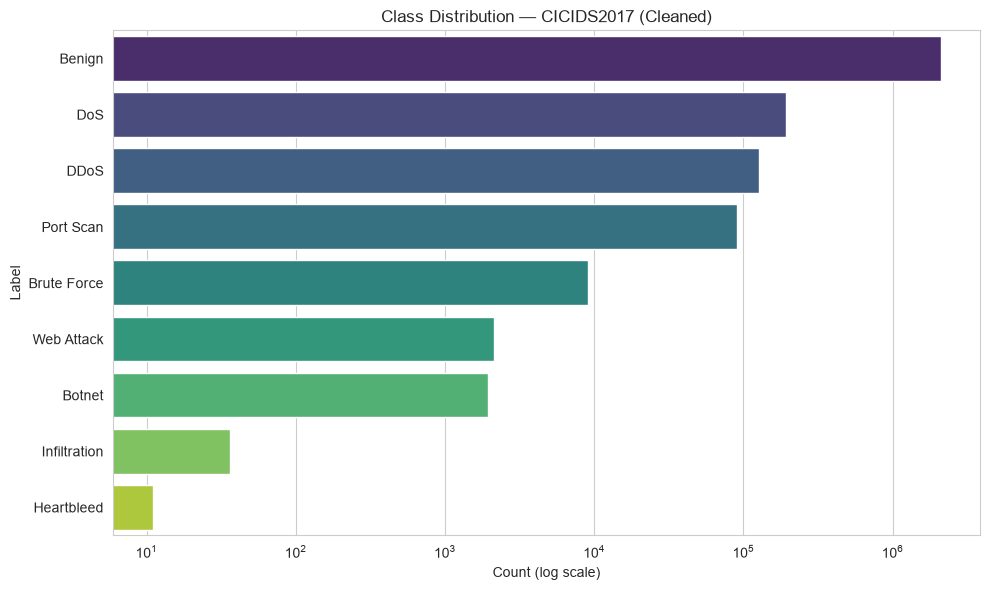

In [4]:
counts = df["Label"].value_counts()

plt.figure(figsize=(10, 6))
sns.barplot(x=counts.values, y=counts.index, palette="viridis")
plt.xscale("log")  # log scale because Benign (2M) vs Heartbleed (11) can't share a linear axis
plt.xlabel("Count (log scale)")
plt.title("Class Distribution — CICIDS2017 (Cleaned)")
plt.tight_layout()
plt.savefig("../reports/figures/class_distribution.png", dpi=150)
plt.show()

In [5]:
key_features = [
    "Flow Duration", "Total Fwd Packets", "Total Backward Packets",
    "Flow Bytes/s", "Flow Packets/s", "Destination Port"
]

df[key_features].describe()

,Flow Duration,Total Fwd Packets,Total Backward Packets,Flow Bytes/s,Flow Packets/s,Destination Port
count,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06
mean,1.659161e+07,1.028174e+01,1.157280e+01,1.410707e+06,4.729188e+04,8.690590e+03
std,3.523276e+07,7.944201e+02,1.056922e+03,2.657084e+07,2.026366e+05,1.901280e+04
min,-1.300000e+01,1.000000e+00,0.000000e+00,-2.610000e+08,-2.000000e+06,0.000000e+00
25%,2.080000e+02,2.000000e+00,1.000000e+00,1.194308e+02,2.023326e+00,5.300000e+01
50%,5.062200e+04,2.000000e+00,2.000000e+00,3.715038e+03,6.974224e+01,8.000000e+01
75%,5.333340e+06,6.000000e+00,5.000000e+00,1.071429e+05,1.785714e+04,4.430000e+02
max,1.200000e+08,2.197590e+05,2.919220e+05,2.071000e+09,4.000000e+06,6.553500e+04


In [6]:
numeric_df = df.select_dtypes(include=[np.number])

# Full correlation matrix on 78 features is unreadable — so we'll
# just flag pairs with very high correlation (likely redundant)
corr_matrix = numeric_df.corr().abs()

# Get upper triangle only, to avoid duplicate pairs (A-B and B-A)
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

high_corr_pairs = (
    upper.stack()
    .reset_index()
    .rename(columns={0: "correlation", "level_0": "feature_1", "level_1": "feature_2"})
)
high_corr_pairs = high_corr_pairs[high_corr_pairs["correlation"] > 0.95].sort_values(
    "correlation", ascending=False
)

print(f"Found {len(high_corr_pairs)} feature pairs with correlation > 0.95")
high_corr_pairs.head(20)

Found 38 feature pairs with correlation > 0.95


,feature_1,feature_2,correlation
215,Total Fwd Packets,Subflow Fwd Packets,1.000000
2354,Fwd PSH Flags,SYN Flag Count,1.000000
2513,Fwd URG Flags,CWE Flag Count,1.000000
978,Bwd Packet Length Mean,Avg Bwd Segment Size,1.000000
669,Fwd Packet Length Mean,Avg Fwd Segment Size,1.000000
294,Total Backward Packets,Subflow Bwd Packets,1.000000
449,Total Length of Bwd Packets,Subflow Bwd Bytes,1.000000
370,Total Length of Fwd Packets,Subflow Fwd Bytes,0.999999
4760,Subflow Fwd Packets,Subflow Bwd Packets,0.999070
217,Total Fwd Packets,Subflow Bwd Packets,0.999070


In [7]:
# Features with only 1 unique value carry zero information —
# no model can learn anything from a column that never changes
constant_features = [col for col in numeric_df.columns if numeric_df[col].nunique() <= 1]
print("Constant features (candidates for removal):")
print(constant_features)

Constant features (candidates for removal):
['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']


In [8]:
summary = {
    "total_rows": len(df),
    "total_features": df.shape[1] - 1,  # excluding Label
    "class_distribution": df["Label"].value_counts().to_dict(),
    "high_corr_pairs_count": len(high_corr_pairs),
    "constant_features": constant_features,
}

import json
with open("../reports/eda_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)

print("EDA summary saved.")

EDA summary saved.


In [9]:
negative_checks = {
    "Flow Duration": (df["Flow Duration"] < 0).sum(),
    "Flow Bytes/s": (df["Flow Bytes/s"] < 0).sum(),
    "Flow Packets/s": (df["Flow Packets/s"] < 0).sum(),
}
print(negative_checks)

{'Flow Duration': np.int64(107), 'Flow Bytes/s': np.int64(78), 'Flow Packets/s': np.int64(107)}
